In [7]:
# --- bootstrap: dodaj katalog projektu do sys.path (dziala z notebooks/ i z root) ---
import sys, pathlib
_p = pathlib.Path.cwd()
while not (_p / 'config.py').exists() and _p != _p.parent:
    _p = _p.parent
if str(_p) not in sys.path:
    sys.path.insert(0, str(_p))
from IPython.display import display

import config


# Notebook 03: analiza błędnie sklasyfikowanych nagłówków

Etap opisuje pomyłki klasyfikatora z trzech stron: jakich tematów dotyczą, jakim słownictwem posługują się w kolejnych półroczach i jak zmienia się w czasie pewność modelu.

Wejście: `data/dane_z_prawdopodobienstwem.csv` z notebooka `01a` oraz zapisany model BERTopic z `01b`.
Wyjście: rysunki w `outputs/figures/`.

Logika siedzi w `src/evaluation.py` i `src/visualization.py`, notebook ją wywołuje i pokazuje wyniki. Model tematyczny budowany osobno na samych pomyłkach powstaje w `src.topics.build_misclassified_topics`, a jego zestawienie trafia do notebooka `04`.

## 1. Kierunki pomyłek

Tabela pokazuje, które pary wydawców model myli ze sobą. Wiersz to wydawca prawdziwy, kolumna przewidywany.

In [8]:
import pandas as pd

from src.evaluation import load_predictions
from src.utils import GAZETY as gazety

df = load_predictions()
df_mis = df[df["label"] != df["predicted_label"]].copy()
print(f"Pomyłek: {len(df_mis)} z {len(df)} nagłówków "
      f"({len(df_mis) / len(df) * 100:.2f}%)")

pd.crosstab(df_mis["label"].map(gazety), df_mis["predicted_label"].map(gazety),
            rownames=["Wydawca prawdziwy"], colnames=["Wydawca przewidziany"])

Pomyłek: 8597 z 55914 nagłówków (15.38%)


Wydawca przewidziany,Niezależna,OKO.press,RP
Wydawca prawdziwy,,,
Niezależna,0,1126,1451
OKO.press,1411,0,2230
RP,1401,978,0


## 2. Tematy pomyłek

Pomyłkom przypisano tematy z modelu ogólnego, zbudowanego na całym korpusie w notebooku `01b`. Odpowiada to na pytanie, czy błędy skupiają się w wybranych obszarach treści, czy rozkładają równomiernie.

In [9]:
from src import topics as tpx

topic_model, sciezka = tpx.load_saved_model()
print(f"Model tematyczny: {sciezka}")

tematy, _ = tpx.assign_topics(
    df_mis["text"].astype(str).tolist(), topic_model,
    cache_csv=config.DATA / "misclassified_general_topics.csv",
)
df_mis["topic"] = tematy

rozklad = df_mis["topic"].value_counts().rename_axis("Topic").reset_index(name="Błędy")
rozklad.merge(topic_model.get_topic_info()[["Topic", "Name"]], on="Topic", how="left").head(11)

Some weights of the model checkpoint at allegro/herbert-base-cased were not used when initializing BertModel: ['cls.predictions.bias', 'cls.predictions.decoder.bias', 'cls.predictions.decoder.weight', 'cls.predictions.transform.LayerNorm.bias', 'cls.predictions.transform.LayerNorm.weight', 'cls.predictions.transform.dense.bias', 'cls.predictions.transform.dense.weight', 'cls.sso.sso_relationship.bias', 'cls.sso.sso_relationship.weight']
- This IS expected if you are initializing BertModel from the checkpoint of a model trained on another task or with another architecture (e.g. initializing a BertForSequenceClassification model from a BertForPreTraining model).
- This IS NOT expected if you are initializing BertModel from the checkpoint of a model that you expect to be exactly identical (initializing a BertForSequenceClassification model from a BertForSequenceClassification model).


Model tematyczny: D:\ARTYKUL\models\bertopic_model_merged
Tematy z cache: misclassified_general_topics.csv (8597 wierszy)


,Topic,Błędy,Name
0,-1,2644,-1_не_це_польщі_на
1,10,1147,10_ziobro_zbigniew_komisją_pegasusa
2,2,459,2_bodnar_prokuratura_sąd_neo
3,17,419,17_moskwa_goworit_putin_putina
4,3,403,3_duda_prezydent_nawrocki_trump
5,11,361,11_michał_szułdrzyński_kolanko_marek
6,22,352,NaN
7,4,262,4_morawiecki_premier_do_się
8,6,193,6_kaczyński_jarosław_pis_nie
9,7,184,7_sejm_ustawy_projekt_ustawa


## 3. Słownictwo pomyłek w czasie

Czołowe terminy TF-IDF w oknach półrocznych. Termin wchodzący do czołówki w jednym oknie i znikający w następnym wskazuje temat, który przez pewien czas mylił model. Okna poniżej 15 nagłówków są pomijane, ponieważ ranking liczony na kilkunastu dokumentach jest przypadkowy.

Okna wyznacza numer miesiąca, a nie `to_period("6M")`: mnożnik przy częstości miesięcznej nie skleja miesięcy w jeden okres, więc wcześniejsze grupowanie wychodziło miesięczne mimo zadanej długości okna.

In [10]:
from src.evaluation import keywords_by_period

keywords_by_period(df_mis, months=6, top=8)

,term 1,term 2,term 3,term 4,term 5,term 6,term 7,term 8
2022-01 - 2022-06,pis,ukrainie,polski,duda,rosji,nato,ukrainy,morawiecki
2022-07 - 2022-12,pis,kaczyński,tusk,prezydent,duda,morawiecki,tuska,rząd
2023-01 - 2023-06,pis,prezydent,duda,ukrainy,tusk,polska,minister,polsce
2023-07 - 2023-12,pis,tusk,tuska,kaczyński,morawiecki,rządu,tvp,sejm
2024-01 - 2024-06,pis,wybory,tusk,kaczyński,prezydent,prezydenta,tuska,duda
2024-07 - 2024-12,pis,tusk,prezydenta,polski,tuska,polska,rząd,ws
2025-01 - 2025-06,nawrocki,pis,trzaskowski,tusk,tuska,nawrockiego,trzaskowskiego,wybory
2025-07 - 2025-12,tusk,nawrocki,pis,tuska,prezydenta,rząd,polska,polski
2026-01 - 2026-06,polsce,polska,pis,2050,usa,prezydent,tusk,ziobro


## 4. Pewność modelu w czasie

Trzy rysunki opisują zachowanie klasyfikatora na całym korpusie, nie tylko na pomyłkach.

Pierwszy pokazuje skład przewidywania: średnie prawdopodobieństwo przypisane każdemu wydawcy, warstwami sumującymi się do jedności. Drugi podaje średnią entropię rozkładu, czyli miarę wahania - zero oznacza przypisanie całej masy jednemu wydawcy, log2(3) = 1,585 rozkład równomierny. Trzeci pokazuje średnie prawdopodobieństwo klasy prawdziwej osobno dla każdego tytułu.

Wartości opisują zachowanie modelu w czasie i nie rozstrzygają, czy źródłem zmiany jest język nagłówków, czy skład korpusu w danym miesiącu.

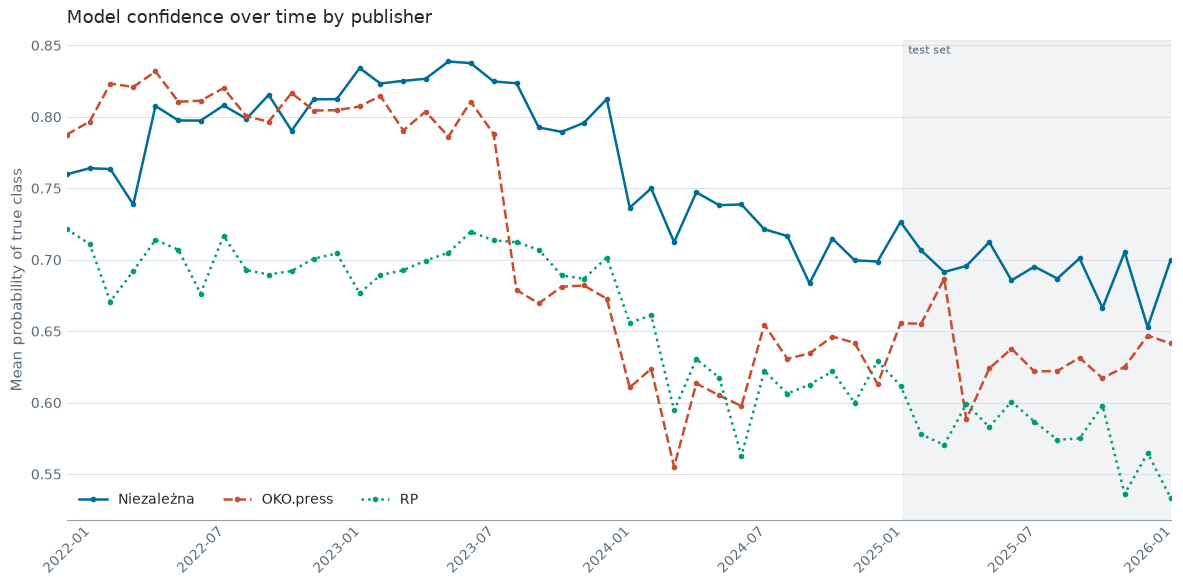

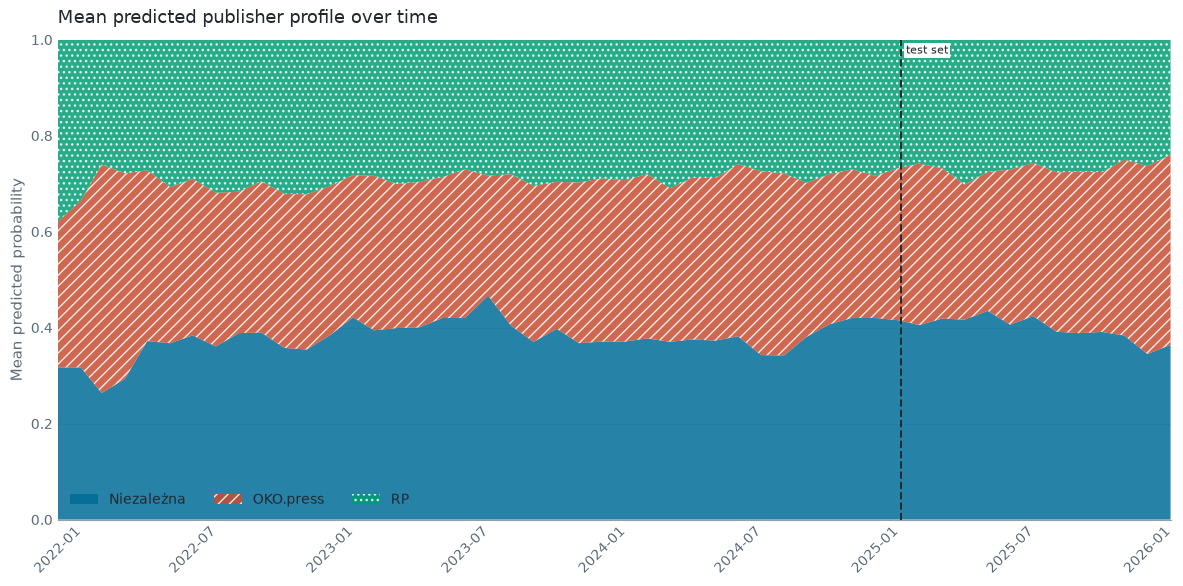

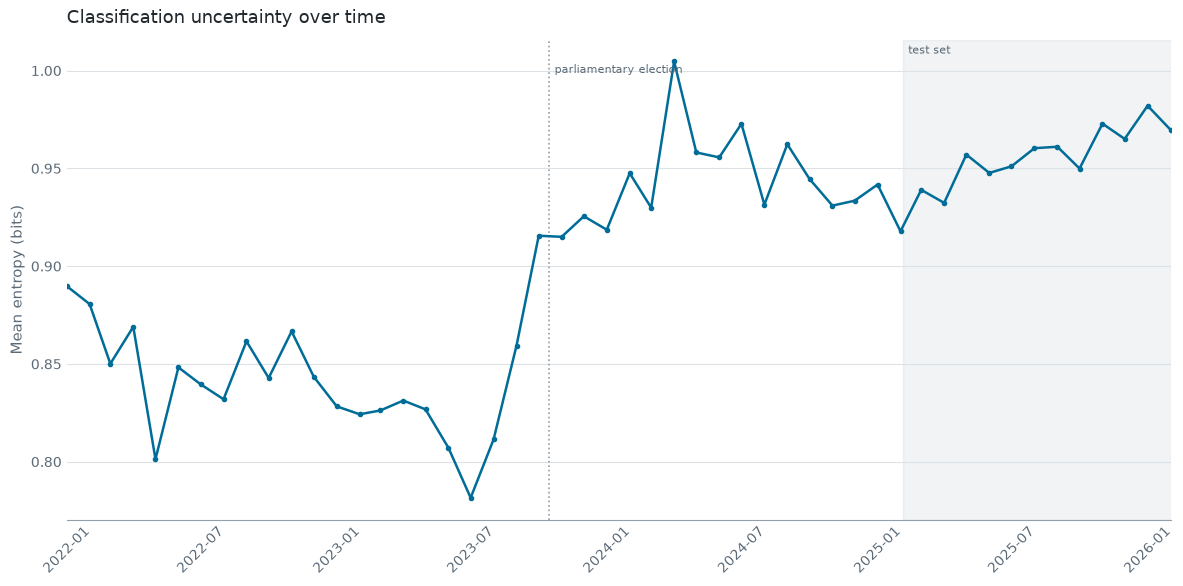

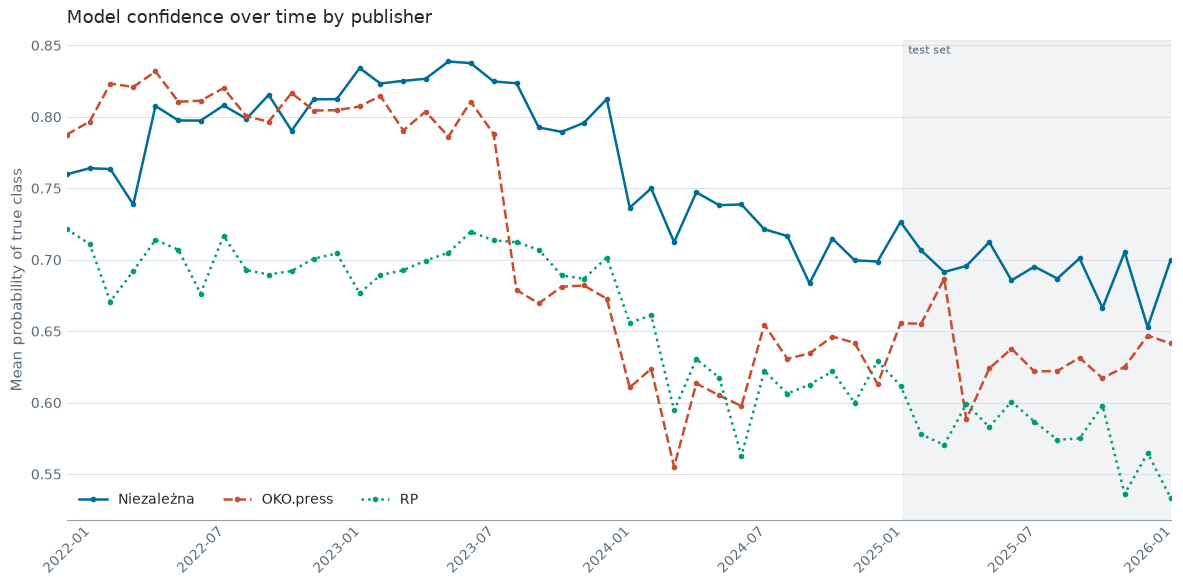

In [11]:
from src.evaluation import confidence_over_time, probability_profile_over_time
from src.visualization import plot_metric_over_time, plot_probability_profile

profil = probability_profile_over_time(df)
pewnosc = confidence_over_time(df)

plot_probability_profile(
    profil,
    save_path=config.FIGURES / "06_profil_prawdopodobienstw.png",
)

plot_metric_over_time(
    profil, "entropy",
    ylabel="Mean entropy (bits)",
    title="Classification uncertainty over time",
    events={"parliamentary election": "2023-10-15"},
    save_path=config.FIGURES / "07_entropia_w_czasie.png",
)

plot_metric_over_time(
    pewnosc, "confidence", by_publisher=True,
    ylabel="Mean probability of true class",
    title="Model confidence over time by publisher",
    save_path=config.FIGURES / "08_pewnosc_w_czasie.png",
)

## 5. Macierz pomyłek na zbiorze testowym

Ten sam rysunek liczy notebook `04`; tutaj służy do odczytania kierunków pomyłek obok analizy powyżej.

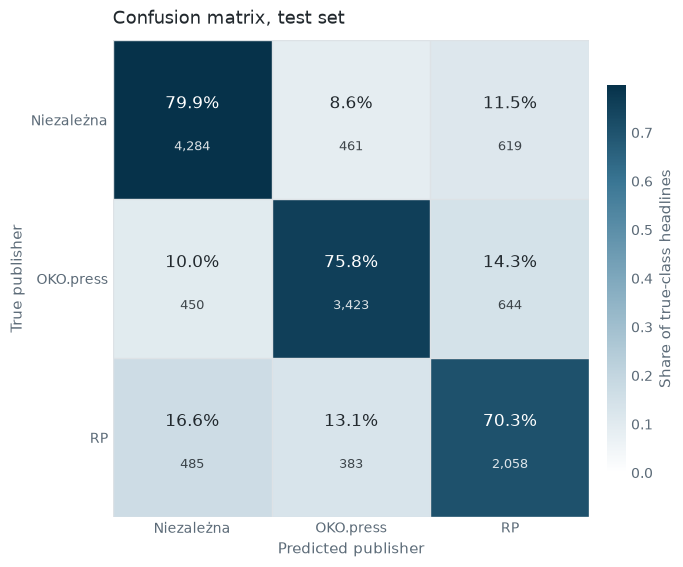

In [12]:
from src.visualization import plot_confusion_matrix

test = df[df["split"] == "test"]
fig = plot_confusion_matrix(
    test["label"], test["predicted_label"],
    title="Confusion matrix, test set",
    save_path=config.FIGURES / "01_macierz_pomylek_test_udzialy.png",
)

## 6. Model tematyczny na samych pomyłkach

Krok opcjonalny, odrębny od sekcji 2. Tam pomyłkom przypisano tematy z modelu ogólnego, zbudowanego na całym korpusie; tutaj model tematyczny budowany jest od nowa, wyłącznie na błędnie sklasyfikowanych nagłówkach testowych i na embeddingach z dostrojonego enkodera. Pierwsze podejście odpowiada na pytanie, w których obszarach treści model się myli; drugie - czy same pomyłki mają własną strukturę tematyczną.

Wynik zasila tabelę w notebooku `04` (`outputs/tabela_tematy_bledow.md`). Krok wymaga GPU i trwa kilkadziesiąt minut, stąd jawne uruchomienie.

In [15]:
import optuna

# Log Optuny to 435 wierszy na przebieg, czyli 124 KB w zapisanym notebooku.
# Wlasne wydruki postepu z src.topics zostaja - przy strojeniu liczonym
# w godzinach pokazuja, czy przebieg idzie.
optuna.logging.set_verbosity(optuna.logging.WARNING)

URUCHOM_TEMATY_POMYLEK = True

if URUCHOM_TEMATY_POMYLEK:
    model_pomylek, wyniki, mis = tpx.build_misclassified_topics(n_trials=435)
    print(f"Tematów: {wyniki['n_topics']} | obserwacje odstające: "
          f"{wyniki['outlier_ratio'] * 100:.1f}% | NPMI: {wyniki['NPMI']:.4f}")
    display(mis.head())
else:
    print("Krok pominięty. Ustaw URUCHOM_TEMATY_POMYLEK = True, aby zbudować model.")

  embeddingi: 64/3042
  embeddingi: 128/3042
  embeddingi: 192/3042
  embeddingi: 256/3042
  embeddingi: 320/3042
  embeddingi: 384/3042
  embeddingi: 448/3042
  embeddingi: 512/3042
  embeddingi: 576/3042
  embeddingi: 640/3042
  embeddingi: 704/3042
  embeddingi: 768/3042
  embeddingi: 832/3042
  embeddingi: 896/3042
  embeddingi: 960/3042
  embeddingi: 1024/3042
  embeddingi: 1088/3042
  embeddingi: 1152/3042
  embeddingi: 1216/3042
  embeddingi: 1280/3042
  embeddingi: 1344/3042
  embeddingi: 1408/3042
  embeddingi: 1472/3042
  embeddingi: 1536/3042
  embeddingi: 1600/3042
  embeddingi: 1664/3042
  embeddingi: 1728/3042
  embeddingi: 1792/3042
  embeddingi: 1856/3042
  embeddingi: 1920/3042
  embeddingi: 1984/3042
  embeddingi: 2048/3042
  embeddingi: 2112/3042
  embeddingi: 2176/3042
  embeddingi: 2240/3042
  embeddingi: 2304/3042
  embeddingi: 2368/3042
  embeddingi: 2432/3042
  embeddingi: 2496/3042
  embeddingi: 2560/3042
  embeddingi: 2624/3042
  embeddingi: 2688/3042
  embedd

Some weights of the model checkpoint at allegro/herbert-base-cased were not used when initializing BertModel: ['cls.predictions.bias', 'cls.predictions.decoder.bias', 'cls.predictions.decoder.weight', 'cls.predictions.transform.LayerNorm.bias', 'cls.predictions.transform.LayerNorm.weight', 'cls.predictions.transform.dense.bias', 'cls.predictions.transform.dense.weight', 'cls.sso.sso_relationship.bias', 'cls.sso.sso_relationship.weight']
- This IS expected if you are initializing BertModel from the checkpoint of a model trained on another task or with another architecture (e.g. initializing a BertForSequenceClassification model from a BertForPreTraining model).
- This IS NOT expected if you are initializing BertModel from the checkpoint of a model that you expect to be exactly identical (initializing a BertForSequenceClassification model from a BertForSequenceClassification model).
[I 2026-10-16 20:25:15,692] Using an existing study with name 'bertopic_misclassified' instead of creating


Optuna (BERTopic na bledach)...
  prob juz w bazie: 67, dokladanych teraz: 435


  trial 501: n_topics=14, outliers=0.608, NPMI=-0.2627

Najlepsza proba #315: NPMI=-0.1010, tematy=14, outliery=0.590
Tematów: 14 | obserwacje odstające: 59.0% | NPMI: -0.1010


,text,label,date,date_parsed,lemmatized_text,predicted_label,probability_topic_0,probability_topic_1,probability_topic_2,split,mis_topic
0,Co ukrywa poseł Trzeciej Drogi? Luki w oświadc...,0,"04.02.2025, 07:31",2025-02-04,ukrywać poseł trzeci drogi luk oświadczenie ma...,2,0.331786,0.148529,0.519684,test,-1
1,"Kierował policją, gdy strzelano do górników, d...",0,"04.02.2025, 22:23",2025-02-04,kierować policja strzelać górnik dostać państw...,1,0.433583,0.460085,0.106332,test,-1
2,"Tusk o 100 mln euro na ""Tarczę Wschód"". Poseł ...",0,"04.02.2025, 10:27",2025-02-04,tusk milion euro tarcza wschód poseł pis nowy ...,2,0.206254,0.034680,0.759066,test,-1
3,Pokazano nowy sondaż. Koalicja 13 grudnia ma p...,0,"04.02.2025, 09:12",2025-02-04,pokazać nowy sondaż koalicja grudzień mieć pow...,2,0.318581,0.044745,0.636674,test,4
4,Byli posłowie dali się wykorzystać reżimowi Łu...,2,04.02.2025 04:30,2025-02-04,posłowie dal wykorzystać reżim łukaszenko dypl...,0,0.780799,0.113118,0.106083,test,1


## Wnioski

### Tematy błędów klasyfikacji

Model tematyczny na 3042 błędnie sklasyfikowanych nagłówkach testowych wyodrębnia 14 tematów, przy udziale obserwacji odstających 59,0% i spójności NPMI -0,101. Największe skupiska dotyczą krajowego sporu politycznego i spraw międzynarodowych, czyli obszarów, w których trzy tytuły opisują te same wydarzenia zachodzącym na siebie słownictwem.

Spójność jest niska, więc tematy opisują zgrubne skupiska, nie rozłączne kategorie. Temat dostało 1247 pomyłek, czyli 41,0%; pozostałe są obserwacjami odstającymi i nie wchodzą do analizy tematycznej. Zestawienie z kierunkami pomyłek: `outputs/tabela_tematy_bledow.md`.

### Ewolucja słów kluczowych

Słowa kluczowe w oknach sześciomiesięcznych wiążą błędy modelu z wydarzeniami okresu: kampanią prezydencką 2025, sporem o prokuraturę i wojną w Ukrainie.

### Rozkłady prawdopodobieństwa

Entropia rozkładu i pewność predykcji w czasie pokazują, czy model myli się z wahaniem, czy pewnie. Wartości te opisują zachowanie modelu i nie rozstrzygają, czy źródłem błędu jest podobieństwo językowe tytułów, czy liczebność klas.
